In [1]:
import logging
import os
import shutil
import tempfile

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import GRSl2bgen

logging.getLogger().setLevel(logging.WARNING)   # logging.INFO to follow the processing

# lighter figures for the documentation
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 72

print(f'GRSl2bgen {GRSl2bgen.__version__}')

GRSl2bgen 1.1.0dev0


In [2]:
l2a_path = '/data/satellite/Sentinel-2/test/S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.0.1dev'
store = os.path.join(l2a_path, os.path.basename(l2a_path) + '.zarr')

layout = xr.open_zarr(store).attrs['multiscales'][0]['layout']
pixel = abs(float(xr.open_zarr(store, group='0').x.diff('x')[0]))
levels = pd.DataFrame([{'level': k, 'group': lev['group'], 'pixels (y x x)': ' x '.join(map(str, lev['shape'])),
                        'pixel size (m)': pixel * lev['scale']} for k, lev in enumerate(layout)]).set_index('level')
levels

,group,pixels (y x x),pixel size (m)
level,,,
0,0,5490 x 5490,20.0
1,1,2745 x 2745,40.0
2,2,1373 x 1373,80.0
3,3,687 x 687,160.0
4,4,344 x 344,320.0


In [3]:
%%time
level = next(k for k, lev in enumerate(layout) if max(lev['shape']) <= 1000)
print(f'quick-look level: {level}, {levels.loc[level, "pixels (y x x)"]} pixels of '
      f'{levels.loc[level, "pixel size (m)"]:.0f} m')

proc = GRSl2bgen.Process(l2a_path, level=level)
proc.execute()
l2b = proc.l2b.l2b_prod.compute()

quick-look level: 3, 687 x 687 pixels of 160 m


CPU times: user 8.1 s, sys: 1.11 s, total: 9.22 s
Wall time: 7.24 s


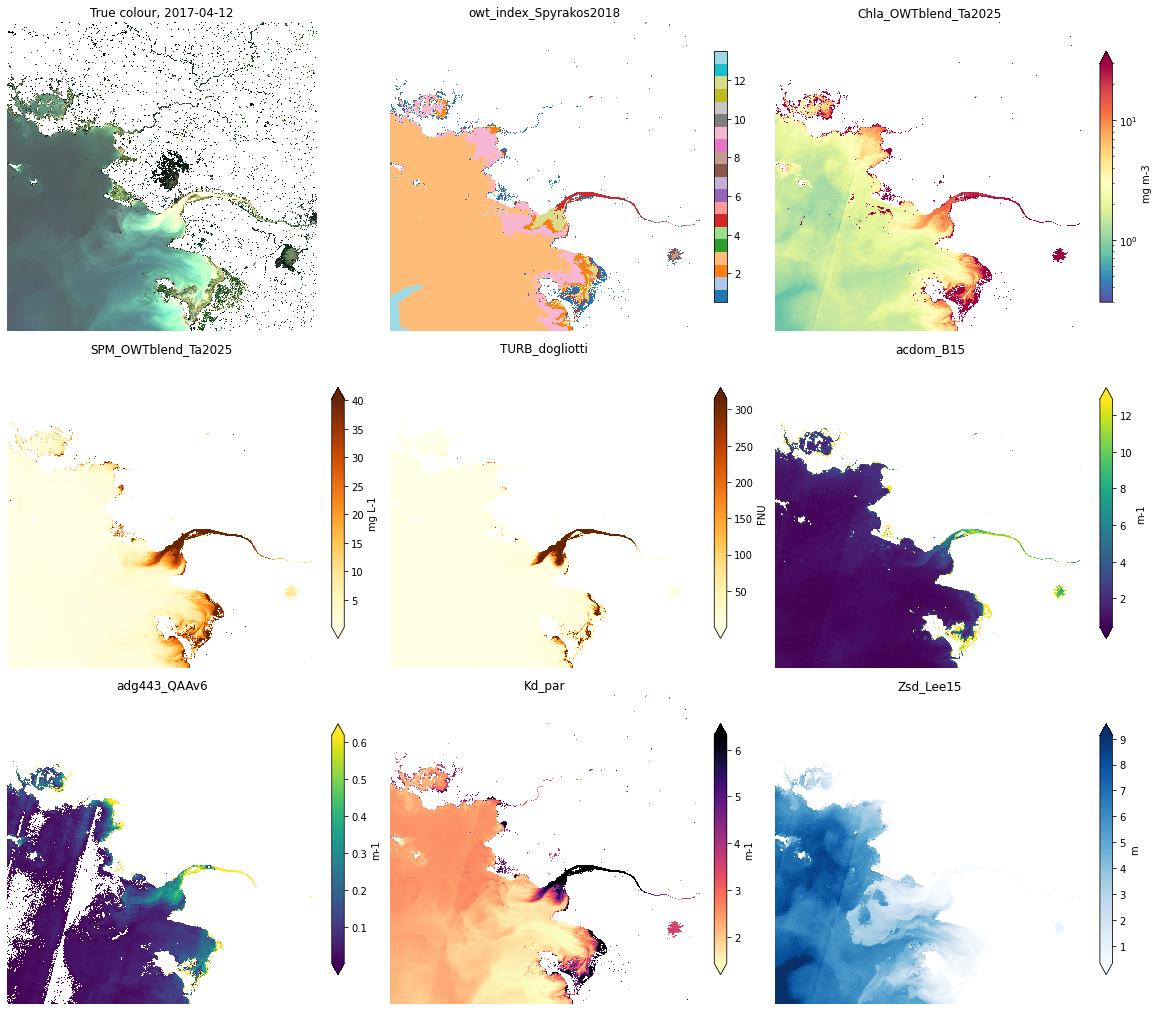

In [4]:
def show(ax, da, title, **kwargs):
    """Map one variable with equal aspect and no axes."""
    da.plot.imshow(ax=ax, cbar_kwargs={'shrink': 0.8, 'label': da.attrs.get('units', '')}, **kwargs)
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.set_axis_off()

rrs = proc.l2a.raster.Rrs
date = str(l2b.time.dt.strftime('%Y-%m-%d').values)
maps = [('owt_index_Spyrakos2018', dict(cmap='tab20', vmin=0.5, vmax=13.5)),
        ('Chla_OWTblend_Ta2025', dict(cmap='Spectral_r', norm=mpl.colors.LogNorm(0.3, 30))),
        ('SPM_OWTblend_Ta2025', dict(cmap='YlOrBr', robust=True)),
        ('TURB_dogliotti', dict(cmap='YlOrBr', robust=True)),
        ('acdom_B15', dict(cmap='viridis', robust=True)),
        ('adg443_QAAv6', dict(cmap='viridis', robust=True)),
        ('Kd_par', dict(cmap='magma_r', robust=True)),
        ('Zsd_Lee15', dict(cmap='Blues', robust=True))]

fig, axs = plt.subplots(3, 3, figsize=(16, 14), constrained_layout=True)
rrs.sel(wl=[665, 560, 490]).plot.imshow(rgb='wl', robust=True, ax=axs[0, 0])
axs[0, 0].set_title(f'True colour, {date}')
axs[0, 0].set_aspect('equal')
axs[0, 0].set_axis_off()
for ax, (var, kwargs) in zip(axs.ravel()[1:], maps):
    da = l2b[var].isel(Nclasses=0) if 'Nclasses' in l2b[var].dims else l2b[var]
    show(ax, da, var, **kwargs)

In [5]:
odir = tempfile.mkdtemp(prefix='grsl2bgen_')
l2b_path = os.path.join(odir, 'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.0.1dev.nc')

proc = GRSl2bgen.Process(l2a_path, l2b_path=l2b_path, level=0)
%time proc.run()

with xr.open_dataset(l2b_path) as ds:
    print(f'{os.path.basename(l2b_path)}: {ds.sizes["y"]} x {ds.sizes["x"]} pixels, '
          f'{len(ds.data_vars)} variables, {os.path.getsize(l2b_path) / 1e6:.0f} MB')

CPU times: user 7min 32s, sys: 38.8 s, total: 8min 10s
Wall time: 2min 32s
S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.0.1dev.nc: 5490 x 5490 pixels, 24 variables, 256 MB


In [6]:
shutil.rmtree(odir)